In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

In [2]:
fifa = pd.read_csv('fifa_eda.csv')

In [3]:
fifa.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18207 entries, 0 to 18206
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID                        18207 non-null  int64  
 1   Name                      18207 non-null  object 
 2   Age                       18207 non-null  int64  
 3   Nationality               18207 non-null  object 
 4   Overall                   18207 non-null  int64  
 5   Potential                 18207 non-null  int64  
 6   Club                      17966 non-null  object 
 7   Value                     17955 non-null  float64
 8   Wage                      18207 non-null  float64
 9   Preferred Foot            18207 non-null  object 
 10  International Reputation  18159 non-null  float64
 11  Skill Moves               18159 non-null  float64
 12  Position                  18207 non-null  object 
 13  Joined                    18207 non-null  int64  
 14  Contra

In [4]:
fifa.head()

,ID,Name,Age,Nationality,Overall,Potential,Club,Value,Wage,Preferred Foot,International Reputation,Skill Moves,Position,Joined,Contract Valid Until,Height,Weight,Release Clause
0,158023,L. Messi,31,Argentina,94,94,FC Barcelona,110500.0,565.0,Left,5.0,4.0,RF,2004,2021-01-01,5.583333,159.0,226500.0
1,20801,Cristiano Ronaldo,33,Portugal,94,94,Juventus,77000.0,405.0,Right,5.0,5.0,ST,2018,2022-01-01,6.166667,183.0,127100.0
2,190871,Neymar Jr,26,Brazil,92,93,Paris Saint-Germain,118500.0,290.0,Right,5.0,5.0,LW,2017,2022-01-01,5.750000,150.0,228100.0
3,193080,De Gea,27,Spain,91,93,Manchester United,72000.0,260.0,Right,4.0,1.0,GK,2011,2020-01-01,6.333333,168.0,138600.0
4,192985,K. De Bruyne,27,Belgium,91,92,Manchester City,102000.0,355.0,Right,4.0,4.0,RCM,2015,2023-01-01,5.916667,154.0,196400.0


In [5]:
fifa.duplicated().sum()

0

In [6]:
fifa.isna().sum()

ID                            0
Name                          0
Age                           0
Nationality                   0
Overall                       0
Potential                     0
Club                        241
Value                       252
Wage                          0
Preferred Foot                0
International Reputation     48
Skill Moves                  48
Position                      0
Joined                        0
Contract Valid Until        289
Height                        0
Weight                        0
Release Clause                0
dtype: int64

In [8]:
pd.set_option('display.float_format', lambda x: '%.2f' % x)

In [9]:
fifa.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,18207.00,214298.34,29965.24,16.00,200315.50,221759.00,236529.50,246620.00
Age,18207.00,25.12,4.67,16.00,21.00,25.00,28.00,45.00
Overall,18207.00,66.24,6.91,46.00,62.00,66.00,71.00,94.00
Potential,18207.00,71.31,6.14,48.00,67.00,71.00,75.00,95.00
Value,17955.00,2444.53,5626.72,10.00,325.00,700.00,2100.00,118500.00
Wage,18207.00,9.73,22.00,0.00,1.00,3.00,9.00,565.00
International Reputation,18159.00,1.11,0.39,1.00,1.00,1.00,1.00,5.00
Skill Moves,18159.00,2.36,0.76,1.00,2.00,2.00,3.00,5.00
Joined,18207.00,2016.42,2.02,1991.00,2016.00,2017.00,2018.00,2018.00
Height,18207.00,5.95,0.22,5.08,5.75,5.92,6.08,6.75


In [3]:
fifa.Club.fillna('Missing', inplace = True )
fifa['Contract Valid Until'].fillna('Missing', inplace = True )
fifa['International Reputation'].fillna(fifa['International Reputation'].median(), inplace = True)
fifa['Skill Moves'].fillna(fifa['Skill Moves'].median(), inplace = True)
fifa['Value'].fillna(fifa['Value'].median(), inplace = True)
fifa['Contract Valid Until'].fillna('Missing', inplace = True )

In [4]:
fifa.isna().sum()

ID                          0
Name                        0
Age                         0
Nationality                 0
Overall                     0
Potential                   0
Club                        0
Value                       0
Wage                        0
Preferred Foot              0
International Reputation    0
Skill Moves                 0
Position                    0
Joined                      0
Contract Valid Until        0
Height                      0
Weight                      0
Release Clause              0
dtype: int64

In [93]:
fifa.head()

,ID,Name,Age,Nationality,Overall,Potential,Club,Value,Wage,Preferred Foot,International Reputation,Skill Moves,Position,Joined,Contract Valid Until,Height,Weight,Release Clause
0,158023,L. Messi,31,Argentina,94,94,FC Barcelona,110500.00,565.00,Left,5.00,4.00,RF,2004,2021-01-01,5.58,159.00,226500.00
1,20801,Cristiano Ronaldo,33,Portugal,94,94,Juventus,77000.00,405.00,Right,5.00,5.00,ST,2018,2022-01-01,6.17,183.00,127100.00
2,190871,Neymar Jr,26,Brazil,92,93,Paris Saint-Germain,118500.00,290.00,Right,5.00,5.00,LW,2017,2022-01-01,5.75,150.00,228100.00
3,193080,De Gea,27,Spain,91,93,Manchester United,72000.00,260.00,Right,4.00,1.00,GK,2011,2020-01-01,6.33,168.00,138600.00
4,192985,K. De Bruyne,27,Belgium,91,92,Manchester City,102000.00,355.00,Right,4.00,4.00,RCM,2015,2023-01-01,5.92,154.00,196400.00


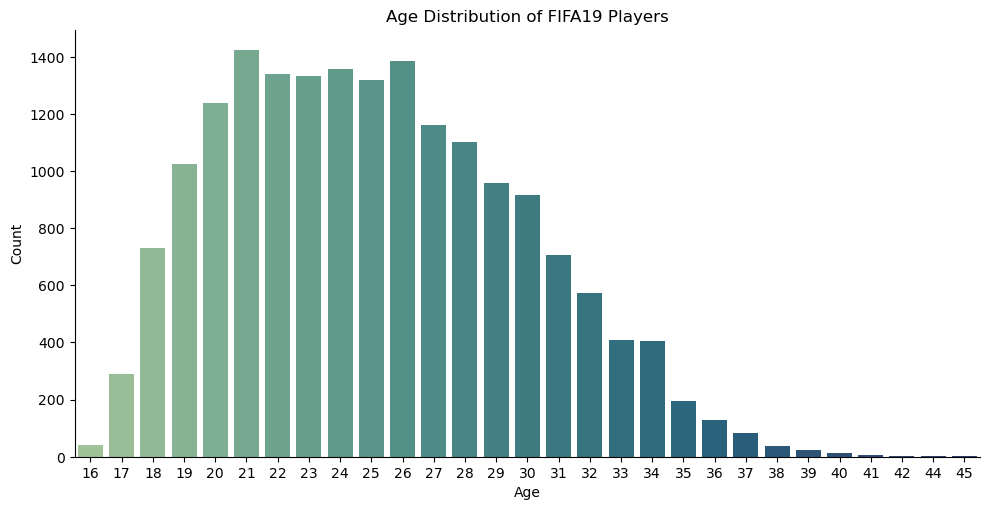

In [8]:
viz_1 = sns.catplot(fifa, x = 'Age', kind = 'count', aspect = 2, palette = 'crest')
viz_1.set_axis_labels('Age','Count')
viz_1.set(title = 'Age Distribution of FIFA19 Players')

In [117]:
top_10_youngest_player = fifa.sort_values(by = 'Age').groupby('Age').first().head(10).reset_index()

In [140]:
top_10_oldest_players = fifa.sort_values(by = 'Age', ascending = False).groupby('Age').first().tail(10).reset_index()

Text(0.5, 1.0, 'Top 10 Oldest Player Value')

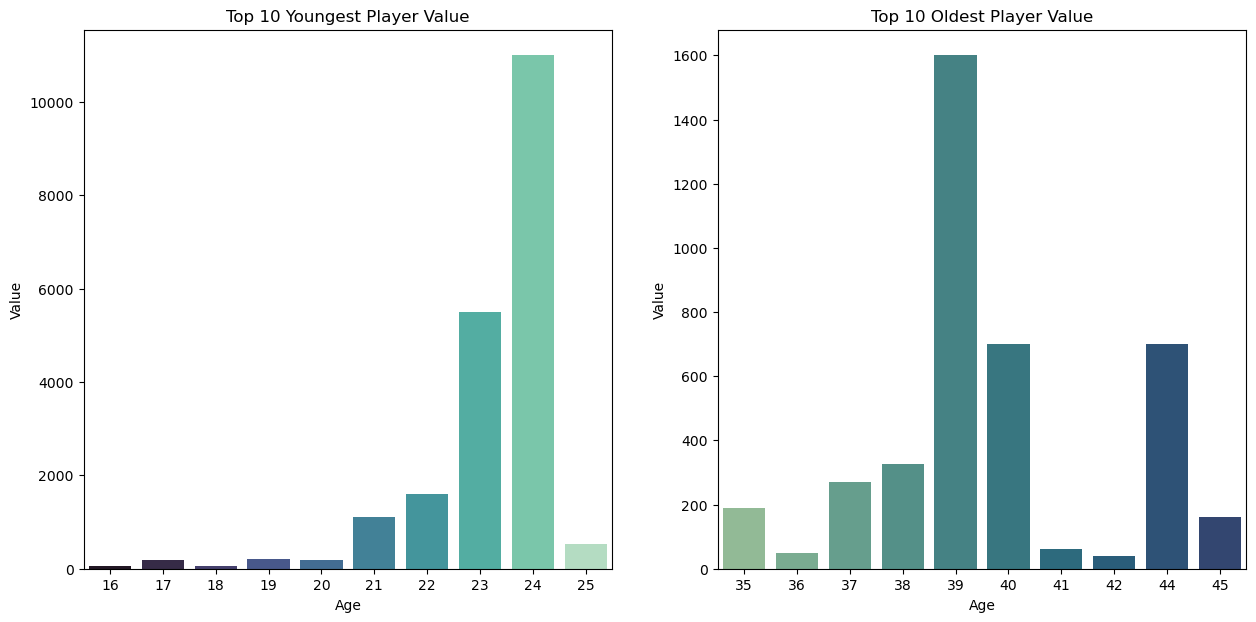

In [348]:
fig, axes = plt.subplots(1,2, figsize = (15,7))
sns.barplot(top_10_youngest_player, x = 'Age', y = 'Value', palette = 'mako', ax = axes[0])
axes[0].set_title('Top 10 Youngest Player Value')

sns.barplot(top_10_oldest_players, x = 'Age', y = 'Value', palette = 'crest', ax = axes[1])
axes[1].set_title('Top 10 Oldest Player Value')

In [180]:
young_players = fifa.loc[fifa.Age <= 25].sort_values(by = 'Age')

In [194]:
young_players_country = young_players.Nationality.value_counts().reset_index().head(10)

In [221]:
oldest_players = fifa.loc[fifa.Age >= 25].sort_values(by = 'Age')

In [222]:
oldest_players_country = oldest_players.Nationality.value_counts().reset_index().head(10)

[Text(0.5, 1.0, 'Countries with Most Old Players')]

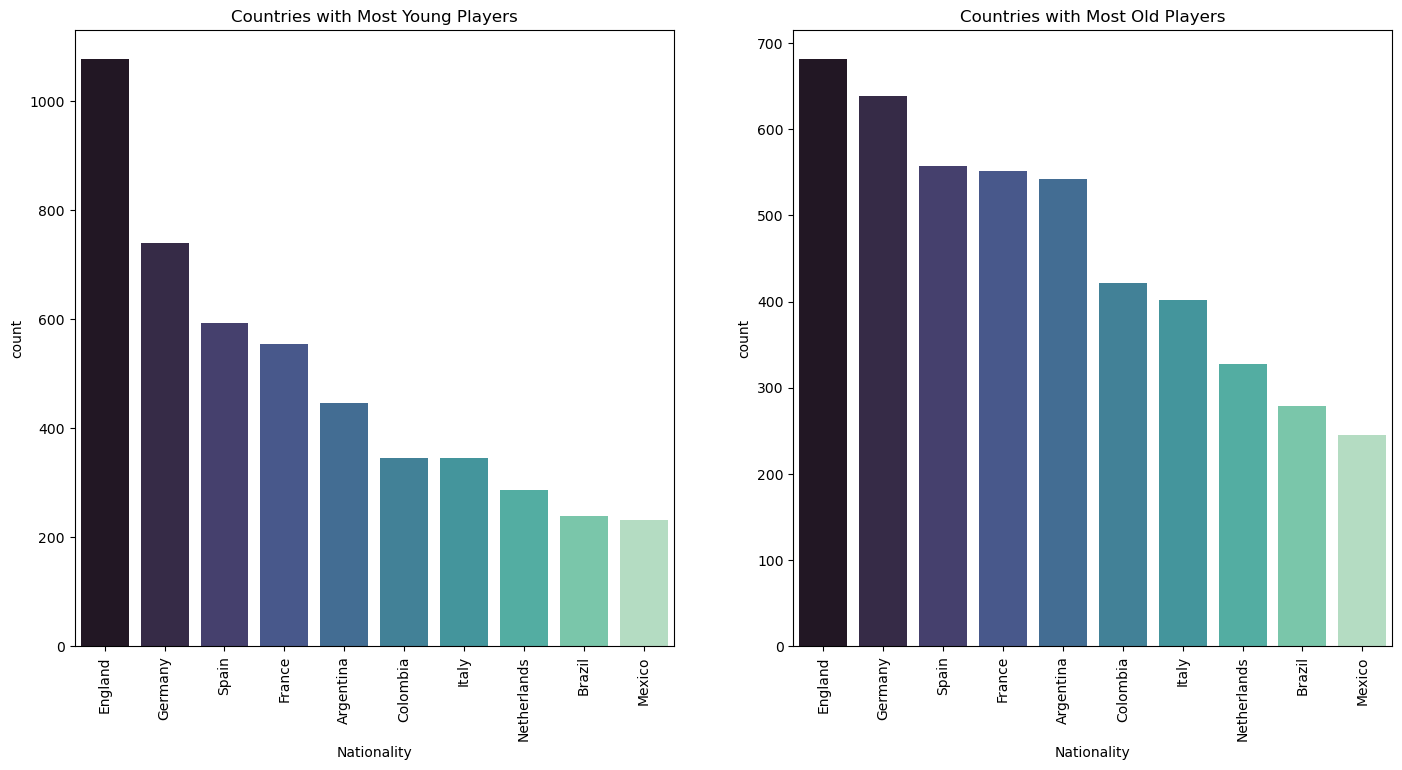

In [227]:
fig, axes = plt.subplots(1,2, figsize = (17,8))
viz_4 = sns.barplot(young_players_country, x = 'Nationality', y = 'count', palette = 'mako', ax = axes[0])
viz_4.set_xticklabels(viz_4.get_xticklabels(), rotation=90)
viz_4.set(title = 'Countries with Most Young Players')
viz_5 = sns.barplot(oldest_players_country, x = 'Nationality', y = 'count', palette = 'mako', ax = axes[1])
viz_5.set_xticklabels(viz_4.get_xticklabels(), rotation=90)
viz_5.set(title = 'Countries with Most Old Players')

In [249]:
top_countries = fifa['Nationality'].value_counts().head(10).reset_index()
top_countries

,Nationality,count
0,England,1662
1,Germany,1198
2,Spain,1072
3,Argentina,937
4,France,914
5,Brazil,827
6,Italy,702
7,Colombia,618
8,Japan,478
9,Netherlands,453


[Text(0, 0.5, 'Number of Players')]

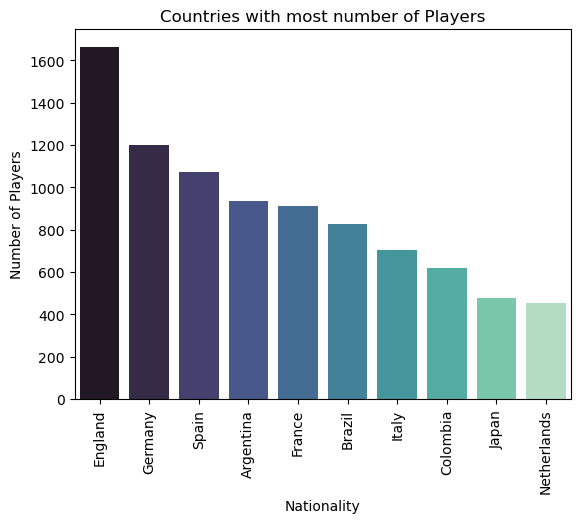

In [258]:
viz_6 = sns.barplot(top_countries, x = 'Nationality', y = 'count', palette = 'mako')
viz_6.set_xticklabels(viz_6.get_xticklabels(), rotation = 90)
viz_6.set(title = 'Countries with most number of Players' )
viz_6.set(ylabel = 'Number of Players')

In [245]:
top_countries_name = top_countries.index
top_countries_name

Index(['England', 'Germany', 'Spain', 'Argentina', 'France', 'Brazil', 'Italy',
       'Colombia', 'Japan', 'Netherlands'],
      dtype='object', name='Nationality')

In [261]:
top_countries_age = fifa.loc[fifa.Nationality.isin(top_countries_name) & fifa.Age]

[Text(0.5, 1.0, 'Age Distribution of Top Countries')]

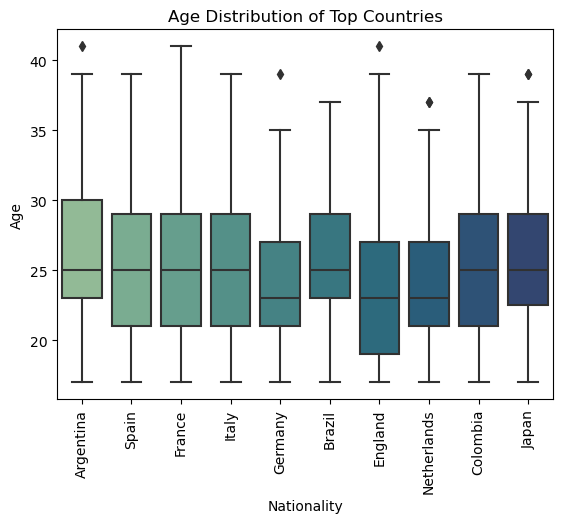

In [273]:
viz_7 = sns.boxplot(top_countries_age, x = 'Nationality', y = 'Age', palette = 'crest')
viz_7.set_xticklabels(viz_7.get_xticklabels(), rotation = 90)
viz_7.set(title = 'Age Distribution of Top Countries')

In [284]:
preferred_foot = fifa['Preferred Foot'].value_counts()/len(fifa)
preferred_foot

Preferred Foot
Right    0.768715
Left     0.231285
Name: count, dtype: float64

Text(0.5, 1.0, 'Players Preferred Foot Distribution')

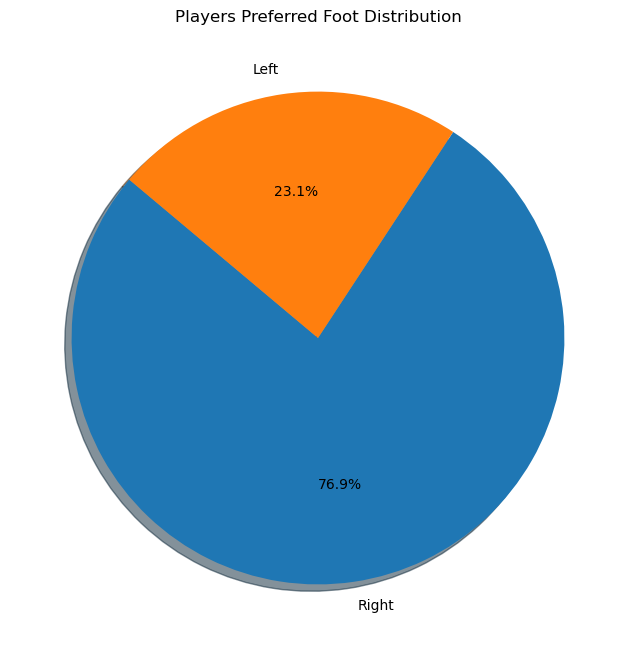

In [310]:
plt.figure(figsize = (8,8))
plt.pie(fifa['Preferred Foot'].value_counts(), labels = fifa['Preferred Foot'].value_counts().index,
        autopct='%1.1f%%', startangle = 140, shadow = True)
plt.title('Players Preferred Foot Distribution')

In [312]:
fifa['International Reputation'].value_counts()

International Reputation
1.0    16580
2.0     1261
3.0      309
4.0       51
5.0        6
Name: count, dtype: int64

In [331]:
most_reputed_players = fifa.loc[fifa['International Reputation'] >= 4.0].nlargest(10, 'International Reputation')

[Text(0, 0, 'L. Messi'),
 Text(1, 0, 'Cristiano Ronaldo'),
 Text(2, 0, 'Neymar Jr'),
 Text(3, 0, 'L. Suárez'),
 Text(4, 0, 'M. Neuer'),
 Text(5, 0, 'Z. Ibrahimović'),
 Text(6, 0, 'De Gea'),
 Text(7, 0, 'K. De Bruyne'),
 Text(8, 0, 'E. Hazard'),
 Text(9, 0, 'L. Modrić')]

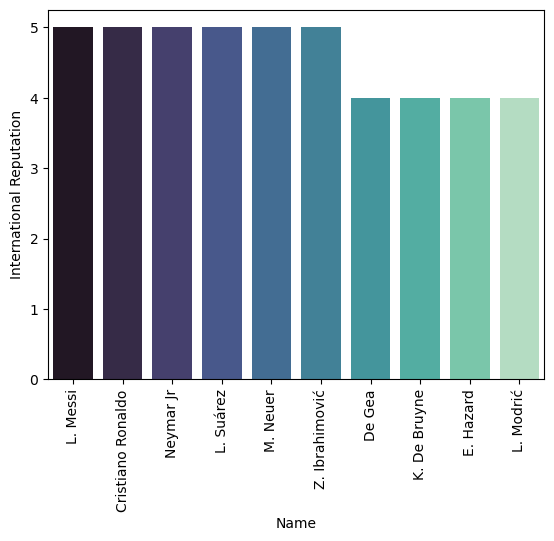

In [361]:
viz_8 = sns.barplot(most_reputed_players, x = 'Name', y = 'International Reputation',palette = 'mako')
viz_8.set_xticklabels(viz_8.get_xticklabels(), rotation = 90)

In [346]:
fifa.groupby('Preferred Foot')['International Reputation'].value_counts()

Preferred Foot  International Reputation
Left            1.0                          3839
                2.0                           290
                3.0                            66
                4.0                            15
                5.0                             1
Right           1.0                         12741
                2.0                           971
                3.0                           243
                4.0                            36
                5.0                             5
Name: count, dtype: int64

In [347]:
fifa.head(2)

,ID,Name,Age,Nationality,Overall,Potential,Club,Value,Wage,Preferred Foot,International Reputation,Skill Moves,Position,Joined,Contract Valid Until,Height,Weight,Release Clause
0,158023,L. Messi,31,Argentina,94,94,FC Barcelona,110500.0,565.0,Left,5.0,4.0,RF,2004,2021-01-01,5.583333,159.0,226500.0
1,20801,Cristiano Ronaldo,33,Portugal,94,94,Juventus,77000.0,405.0,Right,5.0,5.0,ST,2018,2022-01-01,6.166667,183.0,127100.0


In [352]:
high_value_players = fifa.sort_values(by = 'Value', ascending = False).head(10)

[Text(0, 0.5, 'Value in $')]

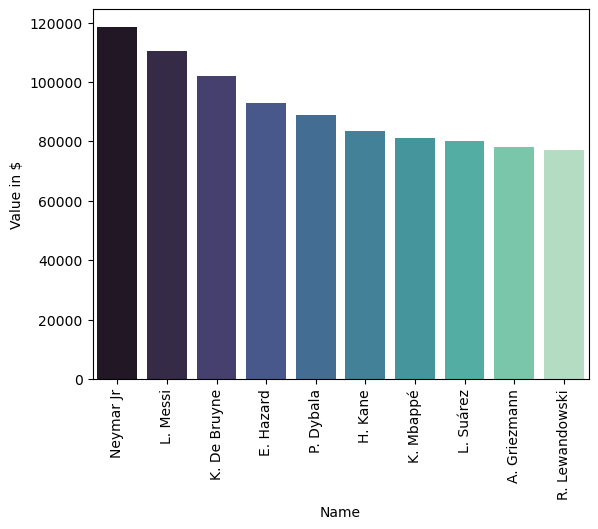

In [366]:
viz_9 = sns.barplot(high_value_players, x = 'Name', y = 'Value', palette = 'mako')
viz_9.set_xticklabels(viz_9.get_xticklabels(), rotation = 90)
viz_9.set(ylabel = 'Value in $')

In [379]:
high_ovr_players = fifa.sort_values(by = 'Overall', ascending = False)
high_ovr_players

,ID,Name,Age,Nationality,Overall,Potential,Club,Value,Wage,Preferred Foot,International Reputation,Skill Moves,Position,Joined,Contract Valid Until,Height,Weight,Release Clause
0,158023,L. Messi,31,Argentina,94,94,FC Barcelona,110500.0,565.0,Left,5.0,4.0,RF,2004,2021-01-01,5.583333,159.0,226500.0
1,20801,Cristiano Ronaldo,33,Portugal,94,94,Juventus,77000.0,405.0,Right,5.0,5.0,ST,2018,2022-01-01,6.166667,183.0,127100.0
2,190871,Neymar Jr,26,Brazil,92,93,Paris Saint-Germain,118500.0,290.0,Right,5.0,5.0,LW,2017,2022-01-01,5.750000,150.0,228100.0
3,193080,De Gea,27,Spain,91,93,Manchester United,72000.0,260.0,Right,4.0,1.0,GK,2011,2020-01-01,6.333333,168.0,138600.0
4,192985,K. De Bruyne,27,Belgium,91,92,Manchester City,102000.0,355.0,Right,4.0,4.0,RCM,2015,2023-01-01,5.916667,154.0,196400.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18190,245569,L. Watkins,18,England,47,67,Cambridge United,60.0,1.0,Right,1.0,2.0,CM,2018,2021-01-01,5.750000,176.0,165.0
18189,240160,A. Kaltner,18,Germany,47,61,SpVgg Unterhaching,60.0,1.0,Right,1.0,2.0,ST,2017,2020-01-01,5.833333,165.0,125.0
18187,240158,C. Ehlich,19,Germany,47,59,SpVgg Unterhaching,40.0,1.0,Right,1.0,2.0,RB,2017,2020-01-01,5.833333,161.0,66.0
18186,240917,Zhang Yufeng,20,China PR,47,64,Beijing Renhe FC,60.0,1.0,Right,1.0,2.0,CM,2016,2019-01-01,5.833333,174.0,167.0


[Text(0.5, 1.0, 'Scatter plot of Players Overall Ratting vs Value by Skill Moves')]

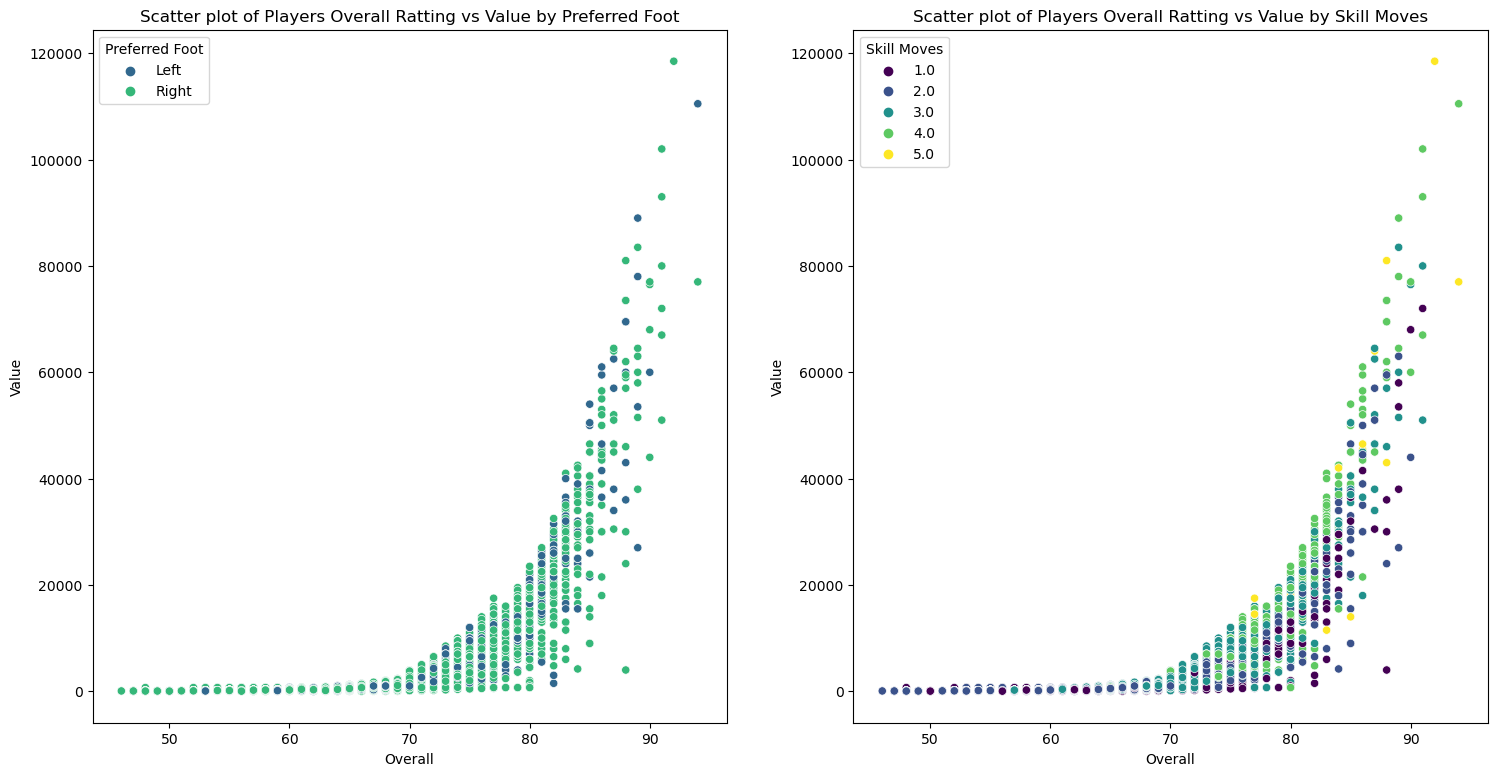

In [408]:
fig, axes = plt.subplots(1,2,figsize = (18,9))
viz_10 = sns.scatterplot(high_ovr_players, x = 'Overall', y = 'Value', alpha = 1, hue = 'Preferred Foot', palette = 'viridis', ax =axes[0])
viz_10.set(title = ('Scatter plot of Players Overall Ratting vs Value by Preferred Foot'))

viz_11 = sns.scatterplot(high_ovr_players, x = 'Overall', y = 'Value', alpha = 1, hue = 'Skill Moves', palette = 'viridis', ax = axes[1])
viz_11.set(title = ('Scatter plot of Players Overall Ratting vs Value by Skill Moves'))

In [3]:
fifa.head()

,ID,Name,Age,Nationality,Overall,Potential,Club,Value,Wage,Preferred Foot,International Reputation,Skill Moves,Position,Joined,Contract Valid Until,Height,Weight,Release Clause
0,158023,L. Messi,31,Argentina,94,94,FC Barcelona,110500.0,565.0,Left,5.0,4.0,RF,2004,2021-01-01,5.583333,159.0,226500.0
1,20801,Cristiano Ronaldo,33,Portugal,94,94,Juventus,77000.0,405.0,Right,5.0,5.0,ST,2018,2022-01-01,6.166667,183.0,127100.0
2,190871,Neymar Jr,26,Brazil,92,93,Paris Saint-Germain,118500.0,290.0,Right,5.0,5.0,LW,2017,2022-01-01,5.750000,150.0,228100.0
3,193080,De Gea,27,Spain,91,93,Manchester United,72000.0,260.0,Right,4.0,1.0,GK,2011,2020-01-01,6.333333,168.0,138600.0
4,192985,K. De Bruyne,27,Belgium,91,92,Manchester City,102000.0,355.0,Right,4.0,4.0,RCM,2015,2023-01-01,5.916667,154.0,196400.0


In [50]:
position_value = fifa.groupby('Position')['Value'].max().reset_index()

In [57]:
position_value.nlargest(10, 'Value')

,Position,Value
14,LW,118500.0
21,RF,110500.0
19,RCM,102000.0
11,LF,93000.0
26,ST,83500.0
22,RM,81000.0
23,RS,80000.0
0,CAM,78000.0
9,LCM,76500.0
5,GK,72000.0


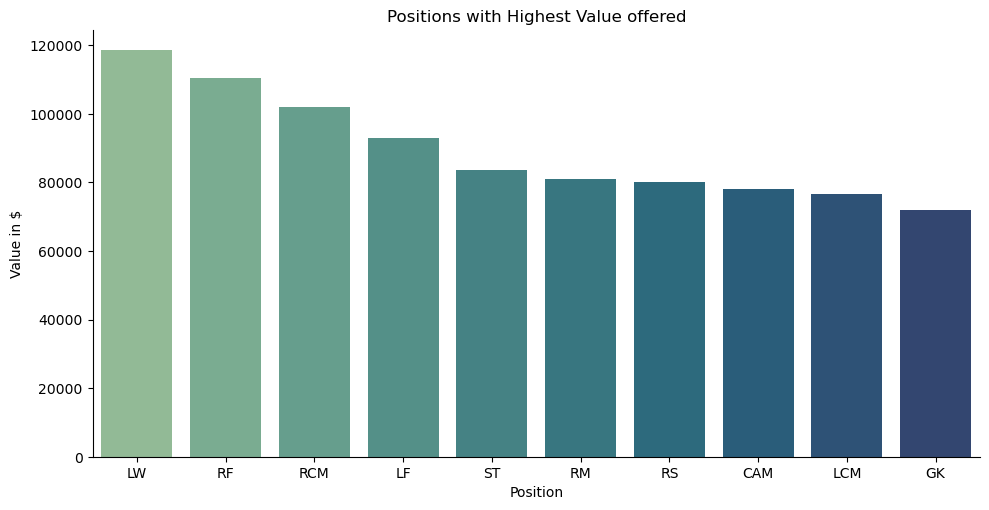

In [56]:
viz_12 = sns.catplot(postion_value.nlargest(10, 'Value'), x = 'Position', y = 'Value', aspect = 2, kind = 'bar', palette = 'crest')
viz_12.set(ylabel = ('Value in $'))
viz_12.set(title = ('Positions with Highest Value offered'))